# Wolfcamp oil production forecasting
## ML Zoomcamp midterm — an end-to-end regression project

**Problem.** Predict the oil produced during months 7–12 of a Wolfcamp well's life using information available after its first six months. This is a supervised regression task: the output is a continuous volume measured in oil barrels (BBL).

**Purpose.** Early production measurements provide a basis for estimating future oil output. This project tests whether machine learning improves those estimates over simple training-median and recent-production-rate benchmarks. It combines observed oil, gas and water volumes with well dimensions, location and available completion attributes, then delivers the selected model through a reproducible prediction service.

**Target:** `First12MonthOil_BBL − First6MonthOil_BBL`. Add the observed six-month oil to the forecast to obtain cumulative first-year oil. Forecasting the incremental volume keeps the evaluation focused on future production.

This notebook loads the shared data, explores the training cohort, demonstrates preprocessing, trains linear and tree-based regressors, tunes their parameters, selects and evaluates a final model, exports its complete pipeline, and calls the prediction API. The accompanying Dockerfile runs the same saved pipeline.

## 1. Setup and source data

Run with Python 3.12 and `requirements-dev.txt`. All paths are relative to this project. The included CSV has 2,105 completion records and 252 fields; the owner confirmed permission to share it for reviewer access. No credentials or external download are required. See `data/raw/README.md` for provenance.

In [1]:
from pathlib import Path
import sys, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.wolfcamp.data import FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES, TARGET, get_xy, split_by_year
from src.wolfcamp.features import MonthSixFeatures, ENGINEERED_NUMERIC
from src.wolfcamp.study import study_data, purged_fit, COMPLETION_FIELDS
from src.wolfcamp.modeling import make_pipeline, preprocessor, score, RecentRateBaseline
from src.wolfcamp.training import training_folds, tune
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
raw=pd.read_csv(ROOT/'data/raw/wolfcamp_wells.csv',low_memory=False)
display(pd.Series({'source_rows':len(raw),'source_columns':raw.shape[1],'unique_source_wells':raw.WellID.nunique()}))
display(raw[['WellID','FirstProdYear','First6MonthOil_BBL','First12MonthOil_BBL']].head())

source_rows            2105
source_columns          252
unique_source_wells    1966
dtype: int64

,WellID,FirstProdYear,First6MonthOil_BBL,First12MonthOil_BBL
0,840300004682082,2020,61280.0,175431.0
1,840420004640853,2018,64922.0,95015.0
2,840420004415806,2018,91149.0,157918.0
3,840420004730792,2018,93149.0,174587.0
4,840420005338124,2019,136569.0,233769.0


## 2. Prepare the study and split chronologically

Keep one valid record per well in FirstProdDate/CompletionID order, require nonnegative six-month oil and twelve-month oil at least as large, and form the incremental target. Deduplication order does not independently certify completion chronology.

The study domain is TVD 7,000–15,000 ft, lateral 4,000–16,000 ft and at least twelve producing months. TVD is a proxy for producing depth. Completion attributes are masked when their dates are missing or later than six calendar months after first production.

Split by first-production year: 2014–18 training, 2019 validation, 2020–21 historical holdout. All data exploration used for modeling below uses the training cohort. Holdout values are reserved for evaluation.

In [2]:
frame=study_data(ROOT/'data/raw/wolfcamp_wells.csv')
train,valid,test=split_by_year(frame)
display(pd.DataFrame([{'cohort':name,'years':f'{int(f.FirstProdYear.min())}–{int(f.FirstProdYear.max())}',
                      'wells':len(f),'completion_records_masked':int(f.completion_masked.sum())}
                     for name,f in [('training',train),('validation',valid),('historical holdout',test)]]))
assert frame.WellID.is_unique
assert (frame[TARGET]>=0).all()
assert set(train.WellID).isdisjoint(valid.WellID) and set(train.WellID).isdisjoint(test.WellID)
print('Allowed predictors:',len(FEATURES),'numeric:',len(NUMERIC_FEATURES),'categorical:',len(CATEGORICAL_FEATURES))
print('Completion fields masked when unverified:',COMPLETION_FIELDS)

,cohort,years,wells,completion_records_masked
0,training,2014–2018,1249,5
1,validation,2019–2019,428,0
2,historical holdout,2020–2021,264,1


Allowed predictors: 25 numeric: 18 categorical: 7
Completion fields masked when unverified: ['Proppant_LBS', 'ProppantIntensity_LBSPerFT', 'TotalWaterPumped_GAL', 'WaterIntensity_GALPerFT', 'FracStages', 'CompletionTime_DAYS', 'SoakTime_DAYS', 'ENVFluidType', 'ENVFracJobType', 'ENVProppantType']


## 3. Explore the training data

Inspect the future-oil distribution, the relationship with observed six-month oil, and coverage by first-production year. Large production values are retained after the validity and domain rules: they may be real high-producing wells and should remain represented in the forecast evaluation.

,count,mean,std,min,50%,max
First3MonthOil_BBL,1249.0,4.067049e+04,2.627992e+04,0.0,38335.0,184432.0
First3MonthGas_MCF,1249.0,1.239048e+05,1.093804e+05,0.0,89272.0,610437.0
First3MonthWater_BBL,1249.0,2.114123e+05,1.527368e+05,0.0,190141.0,809469.0
First6MonthOil_BBL,1249.0,7.859037e+04,4.471671e+04,0.0,73759.0,400334.0
First6MonthGas_MCF,1249.0,2.521415e+05,2.049287e+05,0.0,184876.0,1238414.0
First6MonthWater_BBL,1249.0,4.189852e+05,2.861267e+05,0.0,381382.0,1397596.0
LateralLength_FT,1249.0,6.806548e+03,2.304346e+03,4000.0,6533.0,12867.0
TVD_FT,1249.0,1.067283e+04,9.466786e+02,7163.0,10683.0,12938.0
MD_FT,1249.0,1.776273e+04,2.472144e+03,12091.0,17265.0,23591.0
Proppant_LBS,1150.0,1.383203e+07,6.932129e+06,9700.0,12191449.0,67863768.0


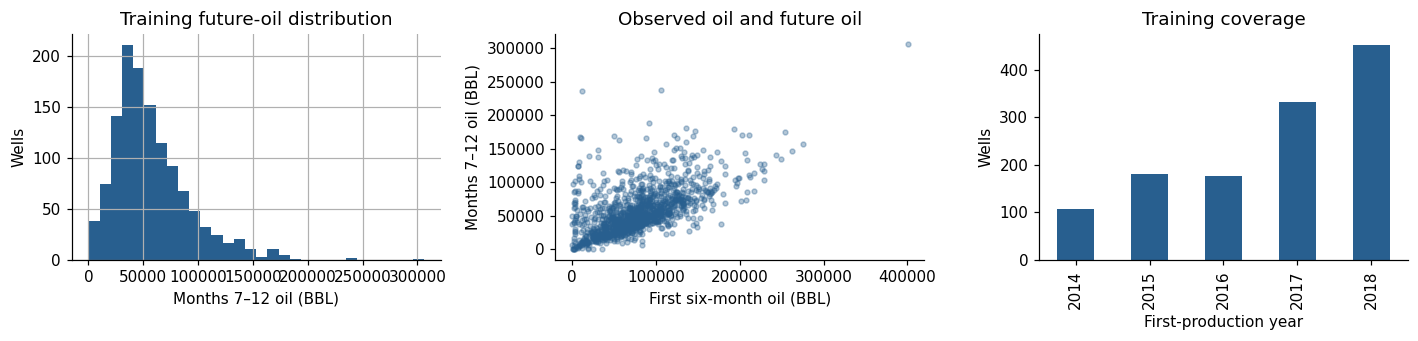

In [3]:
display(train[NUMERIC_FEATURES+[TARGET]].describe().T[['count','mean','std','min','50%','max']])
fig,axes=plt.subplots(1,3,figsize=(13,3.2))
train[TARGET].hist(bins=30,ax=axes[0],color='#285f8f')
axes[0].set(title='Training future-oil distribution',xlabel='Months 7–12 oil (BBL)',ylabel='Wells')
axes[1].scatter(train.First6MonthOil_BBL,train[TARGET],s=10,alpha=.35,color='#285f8f')
axes[1].set(title='Observed oil and future oil',xlabel='First six-month oil (BBL)',ylabel='Months 7–12 oil (BBL)')
train.groupby('FirstProdYear').size().plot.bar(ax=axes[2],color='#285f8f')
axes[2].set(title='Training coverage',xlabel='First-production year',ylabel='Wells')
plt.tight_layout(); plt.show()

### Missing values and categories

Missingness is concentrated in completion-related fields, especially FracStages. Missing values remain unknown rather than being treated as measured zero. The pipeline learns imputation statistics inside each training fold and includes numeric missingness indicators. Sparse completion fields are retained in this chosen pipeline; their presence is not a claim that their measurements are reliable.

Categorical fields describe location, subplay, and completion type. The most frequent training category fills missing entries; one-hot encoding groups categories with fewer than ten training occurrences. Unseen inference categories are handled without failing.

,training_missing_fraction
FracStages,0.906325
ENVProppantType,0.083267
ProppantIntensity_LBSPerFT,0.080064
Proppant_LBS,0.079263
ENVFracJobType,0.076061
ENVFluidType,0.075260
CompletionTime_DAYS,0.075260
WaterIntensity_GALPerFT,0.056845
TotalWaterPumped_GAL,0.056845
SoakTime_DAYS,0.012010


,unique_observed,missing
StateProvince,2,0
County,7,0
ENVSubPlay,4,0
ENVFluidType,4,94
ENVFracJobType,10,95
ENVProppantType,4,104
ENVWellboreType,3,0


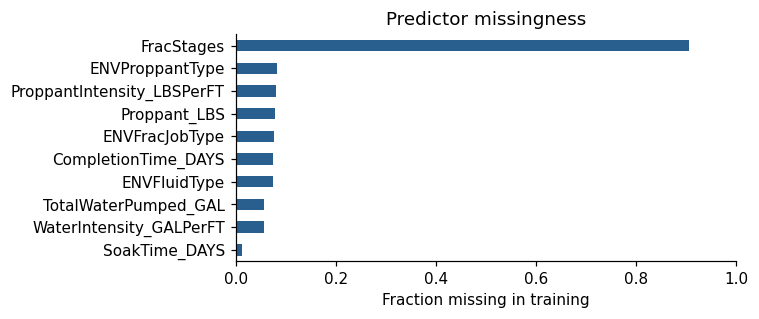

In [4]:
missing=train[FEATURES].isna().mean().sort_values(ascending=False)
display(missing[missing>0].rename('training_missing_fraction').to_frame())
display(pd.DataFrame({'unique_observed':train[CATEGORICAL_FEATURES].nunique(),
                      'missing':train[CATEGORICAL_FEATURES].isna().sum()}))
fig,ax=plt.subplots(figsize=(7,3))
missing[missing>0].sort_values().plot.barh(ax=ax,color='#285f8f')
ax.set(xlabel='Fraction missing in training',xlim=(0,1),title='Predictor missingness')
plt.tight_layout(); plt.show()

### Missingness patterns and feature coverage

This adapts the missingness heatmaps and percentage-bin plots from the author's original practicum notebooks. It uses only the current training cohort and the 25 allowed predictors. Rows are ordered by the number of missing predictors to reveal co-missingness; this ordering is for display only. The bins include every predictor, including complete ones. No missing-column cutoff or extra row filter is applied by this figure.

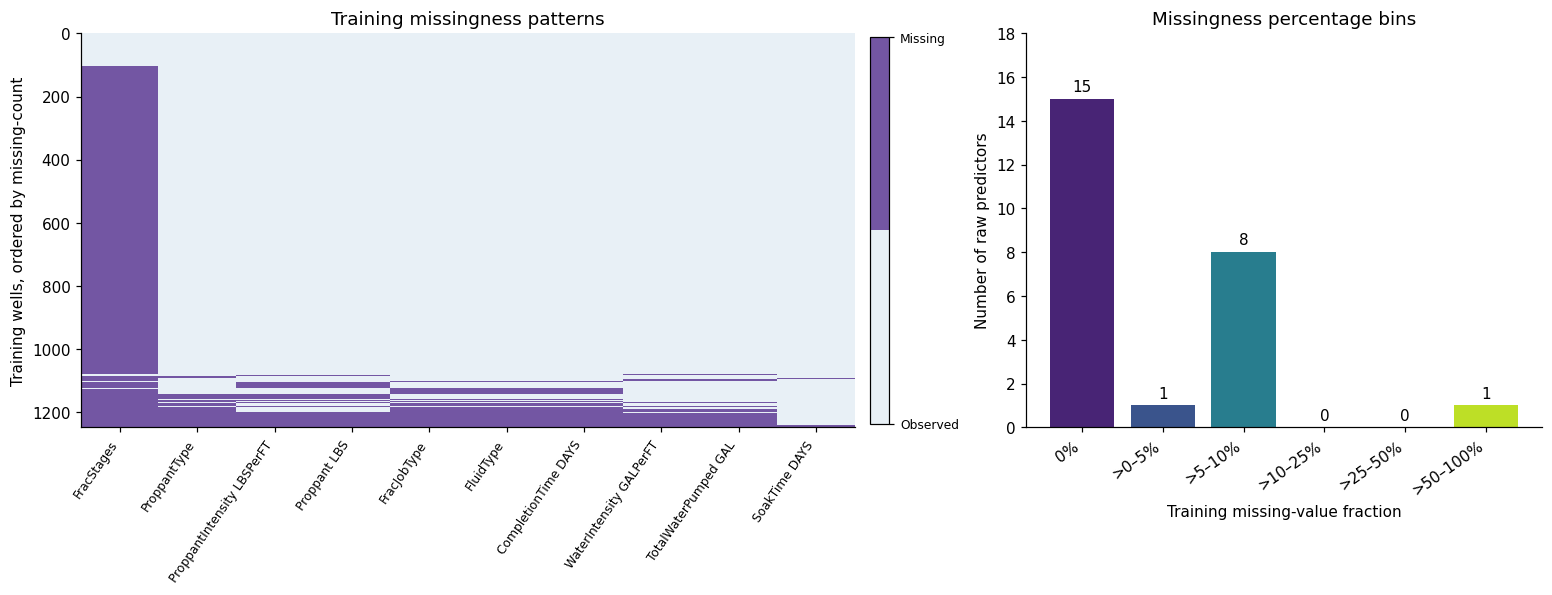

,missingness_bin,predictor_count
0,0%,15
1,>0–5%,1
2,>5–10%,8
3,>10–25%,0
4,>25–50%,0
5,>50–100%,1


In [5]:
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator

missing_matrix=train[FEATURES].isna()
incomplete=missing[missing>0].index.tolist()
row_order=np.argsort(missing_matrix.sum(axis=1).to_numpy(),kind='stable')
fractions=missing_matrix.mean()
bin_counts=np.array([(fractions==0).sum(),((fractions>0)&(fractions<=.05)).sum(),
                     ((fractions>.05)&(fractions<=.10)).sum(),
                     ((fractions>.10)&(fractions<=.25)).sum(),
                     ((fractions>.25)&(fractions<=.50)).sum(),(fractions>.50).sum()])
assert bin_counts.sum()==len(FEATURES)
fig,axes=plt.subplots(1,2,figsize=(14,5.3),gridspec_kw={'width_ratios':[1.5,1]},layout='constrained')
image=axes[0].imshow(missing_matrix[incomplete].iloc[row_order].to_numpy(),
                      aspect='auto',interpolation='nearest',cmap=ListedColormap(['#e8f0f6','#7356a3']),vmin=0,vmax=1)
axes[0].set_xticks(range(len(incomplete)),[c.replace('ENV','').replace('_',' ') for c in incomplete],
                  rotation=55,ha='right',fontsize=8)
axes[0].set(title='Training missingness patterns',ylabel='Training wells, ordered by missing-count')
colorbar=fig.colorbar(image,ax=axes[0],ticks=[0,1],fraction=.025,pad=.02)
colorbar.ax.set_yticklabels(['Observed','Missing'],fontsize=8)
bars=axes[1].bar(range(6),bin_counts,color=plt.colormaps['viridis'](np.linspace(.1,.9,6)))
axes[1].set_xticks(range(6),['0%','>0–5%','>5–10%','>10–25%','>25–50%','>50–100%'],rotation=35,ha='right')
axes[1].bar_label(bars,padding=3)
axes[1].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[1].set(title='Missingness percentage bins',xlabel='Training missing-value fraction',ylabel='Number of raw predictors',ylim=(0,max(bin_counts)+3))
plt.show()
display(pd.DataFrame({'missingness_bin':['0%','>0–5%','>5–10%','>10–25%','>25–50%','>50–100%'],
                      'predictor_count':bin_counts}))

## 4. Build features available at month six

Twenty-five raw inputs generate eleven deterministic features: months 4–6 oil/gas/water, recent-to-early oil ratio, oil per lateral foot, water fraction, gas/oil ratio, stages per thousand feet, and log-scaled proppant/fluid per stage. These describe recent production momentum and completion intensity. Nonpositive ratio denominators become missing; the recent/early ratio is capped at ten. No future production total or target enters the predictors.

In [6]:
X_train,y_train=get_xy(train)
engineered=MonthSixFeatures().fit_transform(X_train)
display(engineered[ENGINEERED_NUMERIC].head())
assert not any('12Month' in c or '9Month' in c or '36Month' in c for c in FEATURES)
assert TARGET not in engineered.columns
display(train[['First3MonthOil_BBL','First6MonthOil_BBL',TARGET,'LateralLength_FT']].corr().round(3))

,oil_months_4_to_6_bbl,gas_months_4_to_6_mcf,water_months_4_to_6_bbl,oil_recent_early_ratio,oil_6_per_lateral_ft,oil_3_per_lateral_ft,water_fraction_6,gas_oil_ratio_6_mcf_per_bbl,frac_stages_per_1000ft,log_proppant_per_stage_lbs,log_fluid_per_stage_gal
0,44424.0,49643.0,18742.0,1.137153,17.636248,8.252218,0.271961,1.305570,NaN,NaN,NaN
1,25208.0,34716.0,20778.0,0.598822,13.558421,8.480258,0.466019,1.171966,NaN,NaN,NaN
2,12614.0,18183.0,66106.0,0.572687,8.237812,5.238050,0.840522,1.624105,NaN,NaN,NaN
3,24778.0,36528.0,121732.0,0.785456,12.821307,7.180970,0.853185,1.432302,NaN,NaN,NaN
4,19392.0,70407.0,562302.0,1.583408,7.649662,2.961074,0.967261,3.600999,NaN,NaN,NaN


,First3MonthOil_BBL,First6MonthOil_BBL,oil_months_7_to_12_bbl,LateralLength_FT
First3MonthOil_BBL,1.000,0.922,0.375,0.402
First6MonthOil_BBL,0.922,1.000,0.583,0.470
oil_months_7_to_12_bbl,0.375,0.583,1.000,0.465
LateralLength_FT,0.402,0.470,0.465,1.000


### Correlation heatmap of training measurements

The author's original correlation-map design is reused on a readable subset of current predictors and the training target. Correlations use pairwise observed measurements, with at least 30 paired observations. Black diagonal outlines flag fields containing missing values. The available sample size therefore varies across pairs, especially for FracStages. The target is included for EDA and remains excluded from model inputs. Correlation does not establish causation or justify automatic feature removal.

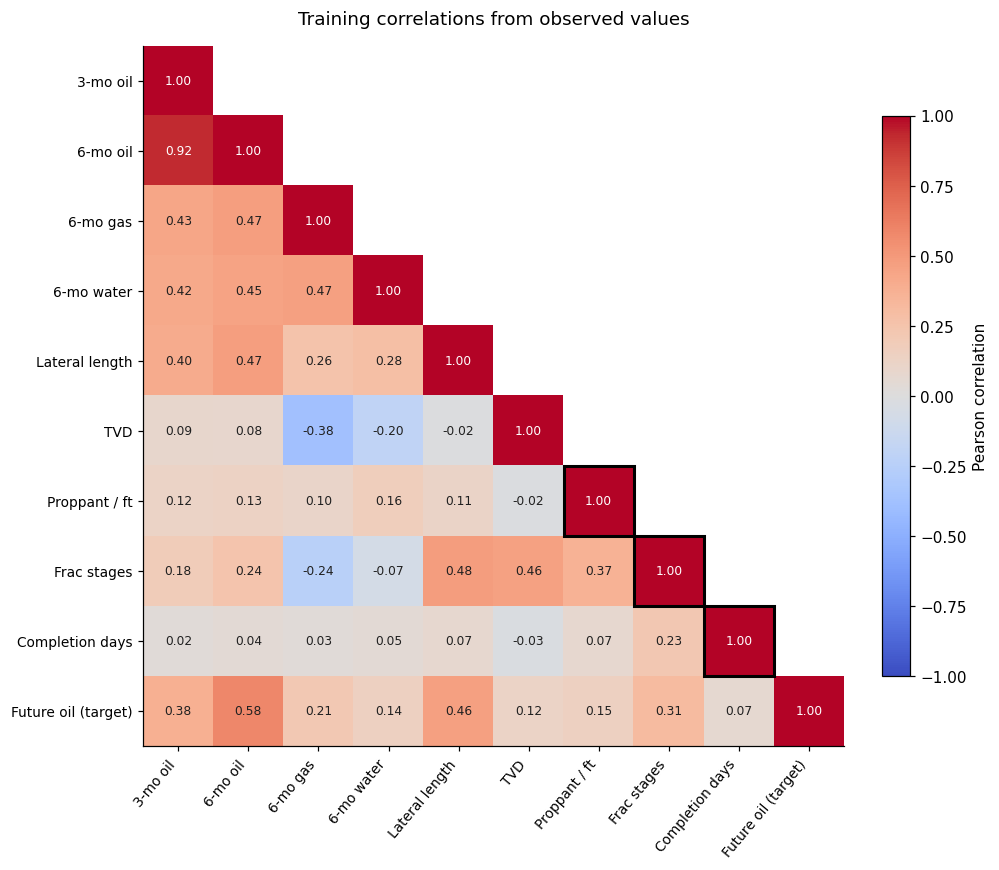

,observed_training_wells
First3MonthOil_BBL,1249
First6MonthOil_BBL,1249
First6MonthGas_MCF,1249
First6MonthWater_BBL,1249
LateralLength_FT,1249
TVD_FT,1249
ProppantIntensity_LBSPerFT,1149
FracStages,117
CompletionTime_DAYS,1155
oil_months_7_to_12_bbl,1249


In [7]:
correlation_columns=['First3MonthOil_BBL','First6MonthOil_BBL','First6MonthGas_MCF',
                     'First6MonthWater_BBL','LateralLength_FT','TVD_FT',
                     'ProppantIntensity_LBSPerFT','FracStages','CompletionTime_DAYS',TARGET]
correlation_labels=['3-mo oil','6-mo oil','6-mo gas','6-mo water','Lateral length','TVD',
                    'Proppant / ft','Frac stages','Completion days','Future oil (target)']
correlation=train[correlation_columns].corr(min_periods=30)
upper=np.triu(np.ones(correlation.shape,dtype=bool),k=1)
fig,ax=plt.subplots(figsize=(9.2,7.8),layout='constrained')
image=ax.imshow(np.ma.masked_where(upper,correlation.to_numpy()),cmap='coolwarm',vmin=-1,vmax=1)
ax.set_xticks(range(len(correlation_columns)),correlation_labels,rotation=50,ha='right',fontsize=9)
ax.set_yticks(range(len(correlation_columns)),correlation_labels,fontsize=9)
for i in range(len(correlation_columns)):
    if train[correlation_columns[i]].isna().any():
        ax.add_patch(plt.Rectangle((i-.5,i-.5),1,1,fill=False,edgecolor='black',linewidth=2))
    for j in range(i+1):
        value=correlation.iloc[i,j]
        if np.isfinite(value): ax.text(j,i,f'{value:.2f}',ha='center',va='center',fontsize=8,
                                        color='white' if abs(value)>.65 else '#202020')
fig.colorbar(image,ax=ax,label='Pearson correlation',shrink=.8)
ax.set_title('Training correlations from observed values',pad=14)
plt.show()
display(train[correlation_columns].notna().sum().rename('observed_training_wells').to_frame())

## 5. Demonstrate imputation and encoding explicitly

Numeric preprocessing applies training-fitted median imputation, adds indicators for fields missing during fitting, and standardizes the resulting columns. Median imputation gives a reproducible fill with limited sensitivity to large values. Scaling is retained consistently across the numerical pipeline; a forest does not require it.

Categorical preprocessing applies training-mode imputation and one-hot encoding. These choices provide a simple, reproducible deployed pipeline. The following cells show the actual fitted medians, filled values, indicator names, modes and encoded columns.

In [8]:
prep=preprocessor()
transformed=prep.fit_transform(engineered,y_train)
numeric=prep.named_transformers_['numeric']
imputer=numeric.named_steps['imputer']
numeric_cols=NUMERIC_FEATURES+ENGINEERED_NUMERIC
display(pd.Series(imputer.statistics_,index=numeric_cols,name='training_median').to_frame())
filled=imputer.transform(engineered[numeric_cols])
examples=[]
for j,col in enumerate(numeric_cols):
    for position in np.flatnonzero(engineered[col].isna().to_numpy())[:1]:
        examples.append({'field':col,'before':engineered.iloc[position][col],
                         'after_imputation':filled[position,j]})
display(pd.DataFrame(examples).head(12))
print('Missingness indicators:',imputer.get_feature_names_out()[len(numeric_cols):].tolist())

,training_median
First3MonthOil_BBL,3.833500e+04
First3MonthGas_MCF,8.927200e+04
First3MonthWater_BBL,1.901410e+05
First6MonthOil_BBL,7.375900e+04
First6MonthGas_MCF,1.848760e+05
First6MonthWater_BBL,3.813820e+05
LateralLength_FT,6.533000e+03
TVD_FT,1.068300e+04
MD_FT,1.726500e+04
Proppant_LBS,1.219145e+07


,field,before,after_imputation
0,Proppant_LBS,NaN,1.219145e+07
1,ProppantIntensity_LBSPerFT,NaN,2.045000e+03
2,TotalWaterPumped_GAL,NaN,1.214141e+07
3,WaterIntensity_GALPerFT,NaN,2.100500e+03
4,FracStages,NaN,2.800000e+01
5,CompletionTime_DAYS,NaN,1.000000e+01
6,SoakTime_DAYS,NaN,1.950000e+01
7,oil_recent_early_ratio,NaN,8.618072e-01
8,water_fraction_6,NaN,8.329878e-01
9,gas_oil_ratio_6_mcf_per_bbl,NaN,2.915911e+00


Missingness indicators: ['missingindicator_Proppant_LBS', 'missingindicator_ProppantIntensity_LBSPerFT', 'missingindicator_TotalWaterPumped_GAL', 'missingindicator_WaterIntensity_GALPerFT', 'missingindicator_FracStages', 'missingindicator_CompletionTime_DAYS', 'missingindicator_SoakTime_DAYS', 'missingindicator_oil_recent_early_ratio', 'missingindicator_water_fraction_6', 'missingindicator_gas_oil_ratio_6_mcf_per_bbl', 'missingindicator_frac_stages_per_1000ft', 'missingindicator_log_proppant_per_stage_lbs', 'missingindicator_log_fluid_per_stage_gal']


### 5.1. Distributions before and after median imputation

This adapts the original histogram-grid approach. Each panel uses the same bins and units for observed training values and the actual median-filled values. Both distributions integrate to one; sample sizes and the filled fraction are labeled. The dashed line is the fitted training median.

These are diagnostic distributions, not known ground truth for missing measurements. Median filling creates a visible concentration at the fill value, especially for the highly incomplete FracStages field. The missingness indicators retain information about which measurements were absent. A visually similar distribution does not demonstrate imputation accuracy or prediction quality.

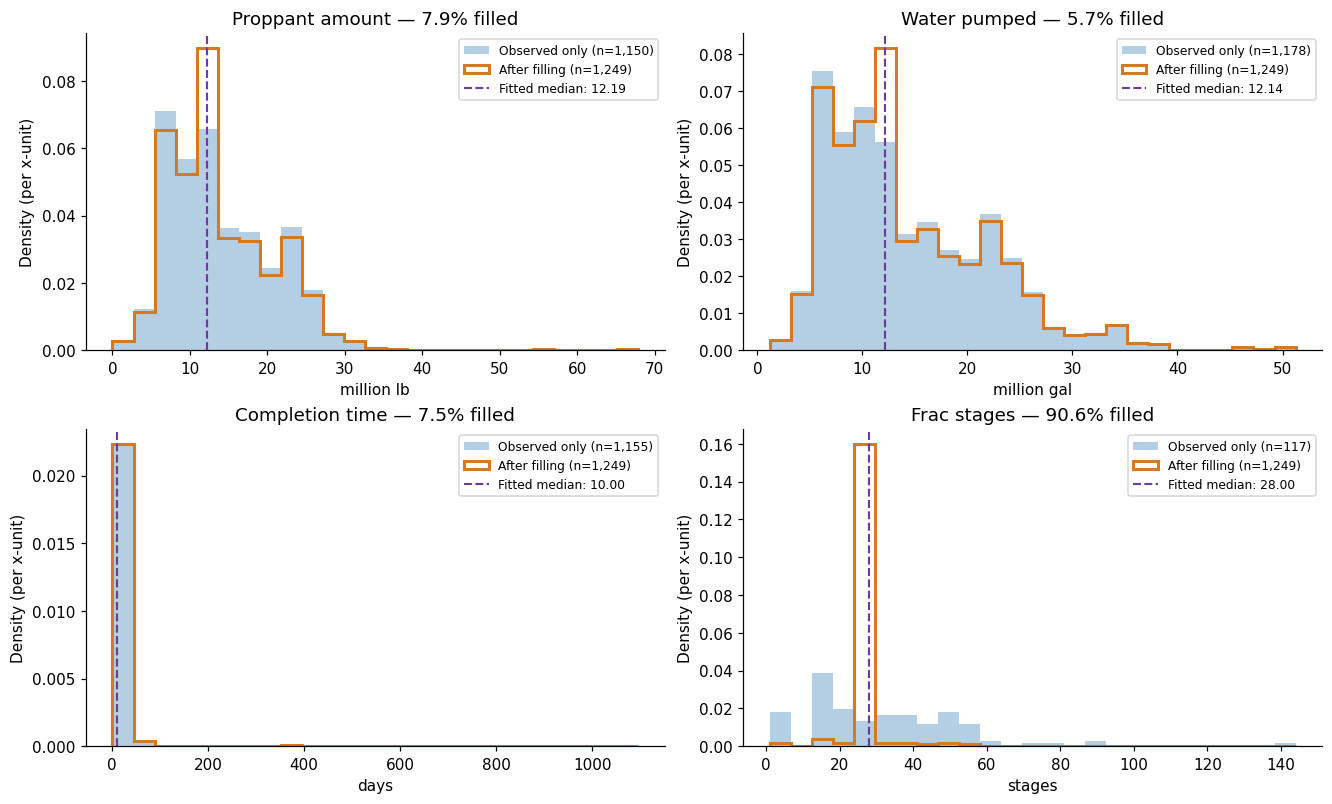

,field,observed_wells,filled_wells,median_in_source_units,observed_SD,after_fill_SD
0,Proppant_LBS,1150,99,12191449.0,6932129.31,6666257.77
1,TotalWaterPumped_GAL,1178,71,12141414.5,7781252.62,7573194.72
2,CompletionTime_DAYS,1155,94,10.0,41.48,39.92
3,FracStages,117,1132,28.0,21.66,6.68


In [9]:
filled_values=pd.DataFrame(filled[:,:len(numeric_cols)],columns=numeric_cols,index=X_train.index)
imputation_panels=[('Proppant_LBS','Proppant amount','million lb',1e6),
                   ('TotalWaterPumped_GAL','Water pumped','million gal',1e6),
                   ('CompletionTime_DAYS','Completion time','days',1),
                   ('FracStages','Frac stages','stages',1)]
fig,axes=plt.subplots(2,2,figsize=(12,7.2),layout='constrained')
distribution_rows=[]
for ax,(column,title,unit,divisor) in zip(axes.flat,imputation_panels):
    observed=engineered[column].dropna().to_numpy()/divisor
    after=filled_values[column].to_numpy()/divisor
    median=imputer.statistics_[numeric_cols.index(column)]/divisor
    absent=int(engineered[column].isna().sum())
    assert np.isfinite(after).all()
    assert np.allclose(after[engineered[column].isna()],median)
    bins=np.histogram_bin_edges(np.concatenate([observed,after]),bins=25)
    ax.hist(observed,bins=bins,density=True,color='#2876b2',alpha=.35,
            label=f'Observed only (n={len(observed):,})')
    ax.hist(after,bins=bins,density=True,histtype='step',color='#d47b21',linewidth=2,
            label=f'After filling (n={len(after):,})')
    ax.axvline(median,color='#6a3d9a',linestyle='--',linewidth=1.4,label=f'Fitted median: {median:.2f}')
    ax.set(title=f'{title} — {absent/len(after):.1%} filled',xlabel=unit,ylabel='Density (per x-unit)')
    ax.legend(fontsize=8)
    distribution_rows.append({'field':column,'observed_wells':len(observed),'filled_wells':absent,
        'median_in_source_units':imputer.statistics_[numeric_cols.index(column)],
        'observed_SD':engineered[column].std(),'after_fill_SD':filled_values[column].std()})
plt.show()
display(pd.DataFrame(distribution_rows).round(2))

### 5.2. Distributions before and after fitted scaling

The original notebooks show histogram grids before and after normalization. Here the same design illustrates the StandardScaler used by this pipeline. The top row shows imputed values in their physical units; the bottom row shows the same wells after training-fitted standardization. Counts and distribution shape are preserved by this affine transformation. Scaling does not make a skewed predictor normally distributed, and Random Forest does not require normal predictors.

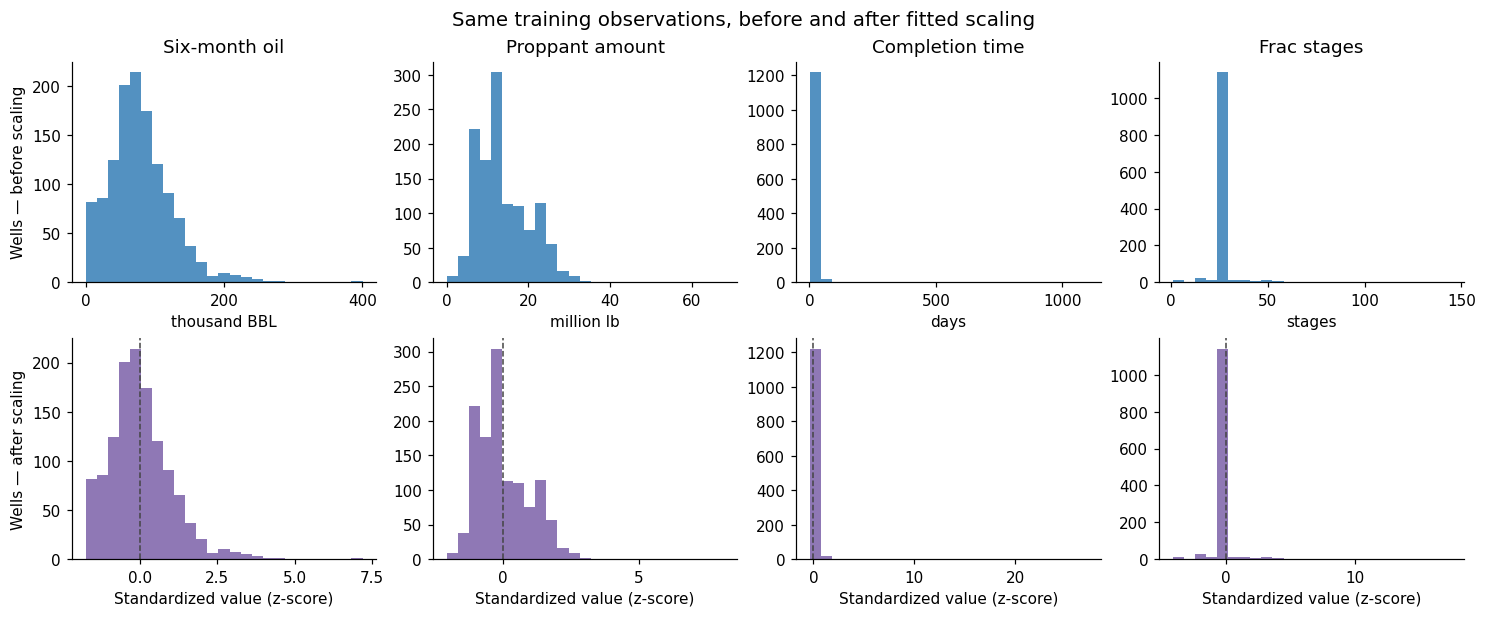

In [10]:
scaled_numeric=numeric.named_steps['scaler'].transform(filled)
scaling_panels=[('First6MonthOil_BBL','Six-month oil','thousand BBL',1e3),
                ('Proppant_LBS','Proppant amount','million lb',1e6),
                ('CompletionTime_DAYS','Completion time','days',1),
                ('FracStages','Frac stages','stages',1)]
fig,axes=plt.subplots(2,4,figsize=(13.4,5.5),sharey='col',layout='constrained')
for j,(column,title,unit,divisor) in enumerate(scaling_panels):
    before=filled_values[column].to_numpy()/divisor
    after=scaled_numeric[:,numeric_cols.index(column)]
    axes[0,j].hist(before,bins=25,color='#2876b2',alpha=.8)
    axes[0,j].set(title=title,xlabel=unit)
    axes[1,j].hist(after,bins=25,color='#7356a3',alpha=.8)
    axes[1,j].axvline(0,color='#444444',linestyle='--',linewidth=1)
    axes[1,j].set(xlabel='Standardized value (z-score)')
    axes[0,j].locator_params(axis='x',nbins=4)
    axes[1,j].locator_params(axis='x',nbins=4)
    assert abs(after.mean())<1e-10 and abs(after.std()-1)<1e-10
axes[0,0].set_ylabel('Wells — before scaling')
axes[1,0].set_ylabel('Wells — after scaling')
fig.suptitle('Same training observations, before and after fitted scaling',fontsize=13)
plt.show()

### 5.3. Categorical imputation and encoding

The fitted mode and one-hot columns below show the categorical representation used by the final pipeline. Missing categories receive the training mode, infrequent observed values are grouped, and the model receives numeric indicator columns.

In [11]:
categorical=prep.named_transformers_['categorical']
display(pd.Series(categorical.named_steps['imputer'].statistics_,index=CATEGORICAL_FEATURES,name='training_mode').to_frame())
onehot=categorical.named_steps['onehot']
encoded_columns=onehot.get_feature_names_out(CATEGORICAL_FEATURES)
print('One-hot columns:',len(encoded_columns))
display(pd.DataFrame({'encoded_column':encoded_columns}))
display(pd.DataFrame(transformed[:5],columns=prep.get_feature_names_out()).iloc[:,:8])
print('Raw / engineered / final transformed feature counts:',len(FEATURES),len(engineered.columns),transformed.shape[1])

,training_mode
StateProvince,TX
County,REEVES
ENVSubPlay,DELAWARE NORTH GAS
ENVFluidType,FRESH WATER
ENVFracJobType,SLICKWATER HC
ENVProppantType,SAND ONLY
ENVWellboreType,SINGLE BORE


One-hot columns: 30


,encoded_column
0,StateProvince_NM
1,StateProvince_TX
2,County_CULBERSON
3,County_LEA
4,County_LOVING
5,County_PECOS
6,County_REEVES
7,County_WARD
8,County_WINKLER
9,ENVSubPlay_DELAWARE NORTH GAS


,numeric__First3MonthOil_BBL,numeric__First3MonthGas_MCF,numeric__First3MonthWater_BBL,numeric__First6MonthOil_BBL,numeric__First6MonthGas_MCF,numeric__First6MonthWater_BBL,numeric__LateralLength_FT,numeric__TVD_FT
0,-0.061078,-0.590340,-1.303197,0.109614,-0.698764,-1.355876,-0.899768,-0.252387
1,0.054265,-0.729333,-1.136084,-0.252498,-0.845821,-1.259552,-0.799917,-0.237592
2,-0.709742,-0.784996,-0.621902,-0.983256,-0.956240,-0.826595,-1.129426,0.706084
3,-0.347343,-0.729489,-0.038175,-0.498142,-0.837058,-0.320508,-1.047809,1.515552
4,-1.082000,-0.735159,1.054895,-1.050394,-0.674697,1.803370,-1.159382,1.160485


Raw / engineered / final transformed feature counts: 25 36 72


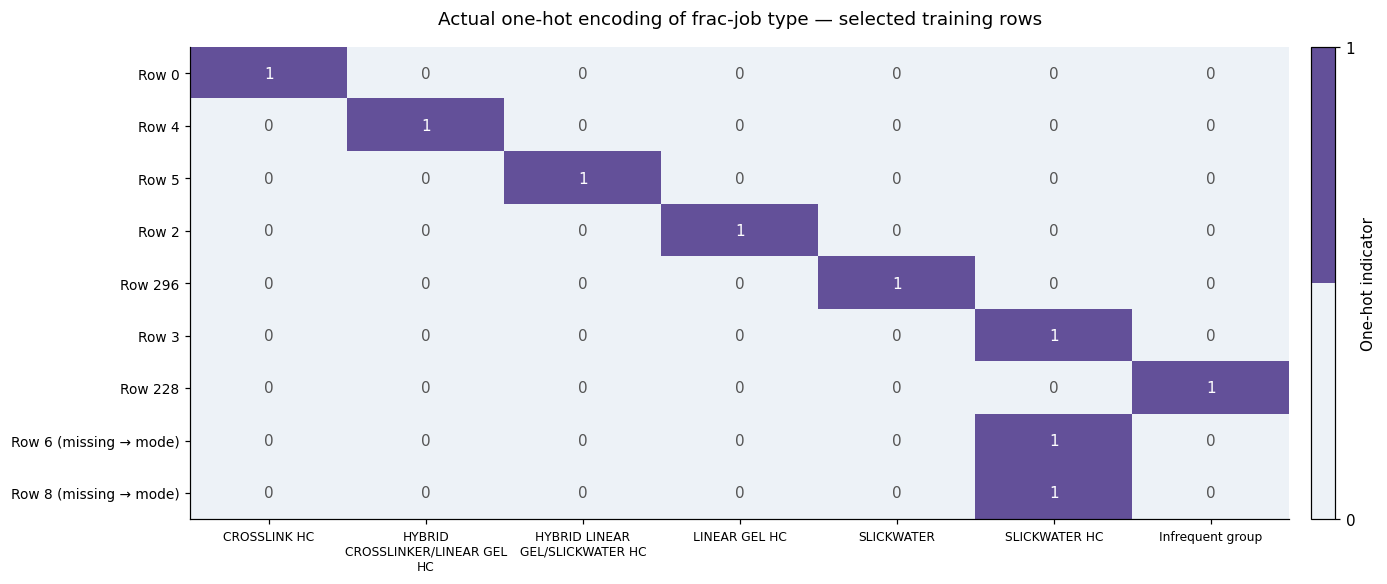

Training mode used for missing frac-job types: SLICKWATER HC


In [12]:
import textwrap
categorical_values=categorical.named_steps['imputer'].transform(engineered[CATEGORICAL_FEATURES])
categorical_encoded=onehot.transform(categorical_values)
field='ENVFracJobType'
indices=[j for j,name in enumerate(encoded_columns) if name.startswith(field+'_')]
block=categorical_encoded[:,indices]
assert np.all(block.sum(axis=1)==1)
selected_rows=[int(np.flatnonzero(block[:,j]>0)[0]) for j in range(block.shape[1]) if np.any(block[:,j]>0)]
selected_rows+=np.flatnonzero(engineered[field].isna().to_numpy())[:2].tolist()
selected_rows=list(dict.fromkeys(selected_rows))
labels=[textwrap.fill(encoded_columns[j].removeprefix(field+'_').replace('infrequent_sklearn','Infrequent group'),22)
        for j in indices]
fig,ax=plt.subplots(figsize=(12.5,5.2),layout='constrained')
image=ax.imshow(block[selected_rows],aspect='auto',cmap=ListedColormap(['#edf2f7','#635099']),vmin=0,vmax=1)
ax.set_xticks(range(len(labels)),labels,fontsize=8)
ax.set_yticks(range(len(selected_rows)),
              [f'Row {i}'+(' (missing → mode)' if pd.isna(engineered.iloc[i][field]) else '') for i in selected_rows],fontsize=9)
for i,row in enumerate(selected_rows):
    for j in range(block.shape[1]):
        value=int(block[row,j]); ax.text(j,i,str(value),ha='center',va='center',color='white' if value else '#555555')
fig.colorbar(image,ax=ax,ticks=[0,1],label='One-hot indicator',fraction=.025,pad=.02)
ax.set_title('Actual one-hot encoding of frac-job type — selected training rows',pad=15)
plt.show()
print('Training mode used for missing frac-job types:',categorical.named_steps['imputer'].statistics_[CATEGORICAL_FEATURES.index(field)])

## 6. Train, tune and select among five regression families

All five models predict the same continuous oil target: ordinary linear regression, regularized Ridge, Decision Tree, Random Forest and XGBoost. Linear regression is an untuned reference. Each tunable family gets twelve configurations: Ridge alpha; tree depth/leaf size; forest tree count/depth/leaf size/sampling; and boosting rounds/rate/depth/regularization/sampling. That is 49 trials and 147 fold fits. The exact grids and seeded samples are declared in `candidate_specs()` and saved in `reports/tuning.json`. Equal trial counts are not an exhaustive search or equal compute budgets.

Use expanding chronological scoring years 2016, 2017 and 2018. A fit label is admitted only when first production plus twelve calendar months is no later than the earliest scoring forecast date (first production plus six months). This approximate label-maturity purge reduces overlap with future labels. It cannot establish actual vendor reporting dates. Every model uses identical deterministic features and fold-local learned preprocessing. Choose the family and parameters with the lowest mean nonnegative-prediction RMSE; validation and holdout targets do not select the winner. See `reports/MODEL_SELECTION_PROTOCOL.md`.

### 6.1. Common evaluation loop

Every configuration below fits a new complete pipeline in each permitted training fold. This loop is the actual training and scoring code, shared unchanged across families.

In [13]:
import warnings
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import ParameterSampler
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor
from src.wolfcamp.modeling import candidate_specs
from src.wolfcamp.training import select_best

display(pd.DataFrame([{'scoring_year':year,'fit_rows':len(fit),'scoring_rows':len(scoring),
                       'purged_rows':int((train.FirstProdYear<year).sum())-len(fit)}
                      for year,fit,scoring in training_folds(train)]))

def evaluate_configs(family, estimator, configurations):
    results=[]
    for parameters in configurations:
        folds=[]
        with warnings.catch_warnings(record=True) as messages:
            warnings.simplefilter('always')
            for year,fit,scoring in training_folds(train):
                X_fit,y_fit=get_xy(fit)
                X_score,y_score=get_xy(scoring)
                fold_pipeline=Pipeline([
                    ('domain_features',MonthSixFeatures()),
                    ('preprocess',preprocessor()),
                    ('model',clone(estimator).set_params(**parameters))])
                fold_pipeline.fit(X_fit,y_fit)
                predictions=np.maximum(0,fold_pipeline.predict(X_score))
                folds.append({'year':year,'fit_rows':len(fit),'scoring_rows':len(scoring),
                    'purged_rows':int((train.FirstProdYear<year).sum())-len(fit),
                    'rmse_bbl':float(root_mean_squared_error(y_score,predictions)),
                    'fit_rmse_bbl':score(y_fit,fold_pipeline.predict(X_fit))['rmse_bbl']})
        results.append({'family':family,'params':parameters,'folds':folds,
                        'cv_rmse_bbl':float(np.mean([f['rmse_bbl'] for f in folds])),
                        'warnings':sorted({str(m.message) for m in messages})})
    display(pd.DataFrame([r['params']|{'CV_RMSE_BBL':r['cv_rmse_bbl']} for r in results]).round(2))
    chosen=min(results,key=lambda r:(r['cv_rmse_bbl'],json.dumps(r['params'],sort_keys=True)))
    print('Best',family,'parameters:',json.dumps(chosen['params'],sort_keys=True))
    print('Best mean CV RMSE:',round(chosen['cv_rmse_bbl'],2),'BBL')
    return results

trials=[]

,scoring_year,fit_rows,scoring_rows,purged_rows
0,2016,205,176,83
1,2017,392,332,72
2,2018,619,453,177


### 6.2. Ordinary linear regression

Fit ordinary least squares as an interpretable linear reference. It has one untuned configuration; Ridge below evaluates regularization.

In [14]:
linear_trials=evaluate_configs('linear_regression',LinearRegression(),[{}])
trials.extend(linear_trials)

,CV_RMSE_BBL
0,28897.63


Best linear_regression parameters: {}
Best mean CV RMSE: 28897.63 BBL


### 6.3. Tune Ridge regression

Twelve alpha values vary the strength of L2 regularization. Stronger regularization shrinks coefficients and can improve generalization when production predictors are correlated.

In [15]:
ridge_grid=[{'alpha':alpha} for alpha in [.01,.03,.1,.3,1.,3.,10.,30.,100.,300.,1000.,3000.]]
ridge_trials=evaluate_configs('ridge',Ridge(),ridge_grid)
trials.extend(ridge_trials)

,alpha,CV_RMSE_BBL
0,0.01,28820.38
1,0.03,28672.34
2,0.10,28281.98
3,0.30,27668.94
4,1.00,26904.77
5,3.00,26429.70
6,10.00,26142.40
7,30.00,26061.19
8,100.00,26260.87
9,300.00,26948.03


Best ridge parameters: {"alpha": 30.0}
Best mean CV RMSE: 26061.19 BBL


### 6.4. Tune Decision Tree regression

Maximum depth controls tree complexity; minimum leaf size prevents splits supported by very few wells. Evaluate all twelve combinations.

In [16]:
tree_grid=[{'max_depth':depth,'min_samples_leaf':leaf}
           for depth in [3,5,8,12] for leaf in [2,5,15]]
tree_trials=evaluate_configs('decision_tree',DecisionTreeRegressor(random_state=42),tree_grid)
trials.extend(tree_trials)

,max_depth,min_samples_leaf,CV_RMSE_BBL
0,3,2,31335.85
1,3,5,29506.63
2,3,15,28211.38
3,5,2,35093.98
4,5,5,29988.79
5,5,15,28112.04
6,8,2,32544.72
7,8,5,30358.16
8,8,15,28230.39
9,12,2,35737.85


Best decision_tree parameters: {"max_depth": 5, "min_samples_leaf": 15}
Best mean CV RMSE: 28112.04 BBL


### 6.5. Tune Random Forest regression

Evaluate six fixed configurations and six additional seeded samples. The full twelve configurations vary tree count, depth, minimum leaf size, feature sampling and bootstrap sample size. All parameters are printed in the output.

In [17]:
forest_grid=[{'n_estimators':160,'max_depth':depth,'min_samples_leaf':leaf,
              'max_features':.75,'max_samples':.7}
             for depth in [5,8,12] for leaf in [2,5]]
forest_space={'n_estimators':[120,160,240],'max_depth':[5,8,12,None],
              'min_samples_leaf':[1,2,5,10],'max_features':[.5,.75,1.],
              'max_samples':[.7,.9,None]}
seen={json.dumps(p,sort_keys=True) for p in forest_grid}
for parameters in ParameterSampler(forest_space,n_iter=100,random_state=42):
    key=json.dumps(parameters,sort_keys=True)
    if key not in seen:
        seen.add(key)
        forest_grid.append(parameters)
    if len(forest_grid)==12: break
forest_trials=evaluate_configs('random_forest',
                             RandomForestRegressor(random_state=42,n_jobs=2),forest_grid)
trials.extend(forest_trials)

,n_estimators,max_depth,min_samples_leaf,max_features,max_samples,CV_RMSE_BBL
0,160,5.0,2,0.75,0.7,25880.87
1,160,5.0,5,0.75,0.7,25742.35
2,160,8.0,2,0.75,0.7,25687.52
3,160,8.0,5,0.75,0.7,25712.80
4,160,12.0,2,0.75,0.7,25777.07
5,160,12.0,5,0.75,0.7,25731.45
6,160,NaN,2,1.00,NaN,26150.30
7,120,5.0,2,1.00,0.7,25999.68
8,120,8.0,1,1.00,0.7,26459.65
9,120,5.0,5,0.50,NaN,25865.79


Best random_forest parameters: {"max_depth": null, "max_features": 0.75, "max_samples": null, "min_samples_leaf": 5, "n_estimators": 240}
Best mean CV RMSE: 25623.0 BBL


### 6.6. Tune XGBoost regression

Evaluate twelve seeded configurations across boosting rounds, learning rate, depth, child weight, row/column sampling and L1/L2 regularization. The fixed squared-error objective fits a continuous target. These parameters balance model capacity and regularization.

In [18]:
boosting_space={'n_estimators':[100,200,350],'learning_rate':[.025,.05,.1],
                'max_depth':[2,3,4],'min_child_weight':[1,3,8],
                'subsample':[.65,.8,1.],'colsample_bytree':[.65,.8,1.],
                'reg_lambda':[1,10,40,100],'reg_alpha':[0,1,10]}
boosting_grid=list(ParameterSampler(boosting_space,n_iter=12,random_state=42))
boosting_trials=evaluate_configs('xgboost',XGBRegressor(objective='reg:squarederror',
                     tree_method='hist',random_state=42,n_jobs=2),boosting_grid)
trials.extend(boosting_trials)

,subsample,reg_lambda,reg_alpha,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,CV_RMSE_BBL
0,0.80,100,10,100,3,3,0.05,1.00,28511.40
1,1.00,40,10,350,3,4,0.02,0.65,26715.05
2,1.00,1,10,350,3,3,0.10,0.80,25981.49
3,0.80,40,0,100,1,3,0.10,0.80,26296.43
4,0.80,100,0,100,8,4,0.10,0.80,27199.32
5,0.80,1,0,100,3,3,0.02,1.00,26014.40
6,0.80,100,10,100,3,3,0.02,0.65,30661.68
7,0.80,100,10,350,3,3,0.05,0.80,26636.45
8,0.80,100,10,200,1,4,0.10,0.80,26819.08
9,0.65,40,0,100,8,3,0.10,1.00,26513.04


Best xgboost parameters: {"colsample_bytree": 0.8, "learning_rate": 0.1, "max_depth": 3, "min_child_weight": 3, "n_estimators": 350, "reg_alpha": 10, "reg_lambda": 1, "subsample": 1.0}
Best mean CV RMSE: 25981.49 BBL


### 6.7. Select the final family and parameters

Rank all 49 evaluated configurations by mean training-CV RMSE. The checks below establish that the inline notebook search matches the training script's declared configurations. The selected family is determined by scores.

In [19]:
assert [{'family':r['family'],'params':r['params']} for r in trials]==list(candidate_specs())
assert len(trials)==49 and sum(len(r['folds']) for r in trials)==147
best=select_best(trials)
family_best=pd.DataFrame([{'family':r['family'],'CV_RMSE_BBL':r['cv_rmse_bbl'],'parameters':r['params']} for r in trials]).sort_values('CV_RMSE_BBL').drop_duplicates('family')
display(family_best)
print('Trials:',len(trials),'fold fits:',sum(len(r['folds']) for r in trials))
print('Chosen family:',best['family'],'hyperparameters:',best['params'])
display(pd.DataFrame(best['folds']))

,family,CV_RMSE_BBL,parameters
35,random_forest,25623.002838,"{'n_estimators': 240, 'min_samples_leaf': 5, '..."
39,xgboost,25981.494959,"{'subsample': 1.0, 'reg_lambda': 1, 'reg_alpha..."
8,ridge,26061.190197,{'alpha': 30.0}
18,decision_tree,28112.039444,"{'max_depth': 5, 'min_samples_leaf': 15}"
0,linear_regression,28897.630550,{}


Trials: 49 fold fits: 147
Chosen family: random_forest hyperparameters: {'n_estimators': 240, 'min_samples_leaf': 5, 'max_samples': None, 'max_features': 0.75, 'max_depth': None}


,year,fit_rows,scoring_rows,purged_rows,rmse_bbl,fit_rmse_bbl
0,2016,205,176,83,25653.575231,9270.56
1,2017,392,332,72,27867.153779,11310.81
2,2018,619,453,177,23348.279504,13585.66


Training error and future-year CV error quantify different performance. A lower training error is expected for a flexible ensemble; the gap and year-to-year variation motivate depth/leaf regularization and cautious interpretation. RMSE emphasizes large misses, MAE describes average absolute error, and R² measures variance explained on the incremental target.

## 7. Validate, refit and evaluate

Fit the tuned pipeline on the purged 2014–18 data and report 2019 validation performance. Then refit that fixed specification on the purged 2014–19 data, leaving 2020–21 for the final historical evaluation.

**Evidence limit:** this 2020–21 cohort was inspected during prior development. It is a reused historical holdout, not fresh independent prospective evidence. The scores below describe the fitted artifact and this specific evaluation protocol.

In [20]:
fit_valid=purged_fit(train,valid)
validation_model=make_pipeline(best['params'],family=best['family']).fit(*get_xy(fit_valid))
Xv,yv=get_xy(valid)
validation_metrics=score(yv,validation_model.predict(Xv))
print('2019 validation:',validation_metrics,'fit wells:',len(fit_valid))
final_fit=purged_fit(pd.concat([train,valid]),test)
model=make_pipeline(best['params'],family=best['family']).fit(*get_xy(final_fit))
Xt,yt=get_xy(test)
pred=np.maximum(0,model.predict(Xt))
metrics=score(yt,pred)
recent=RecentRateBaseline().fit(*get_xy(final_fit))
display(pd.DataFrame({best['family']:metrics,'recent-rate benchmark':score(yt,recent.predict(Xt)),
                      'training-median benchmark':score(yt,np.repeat(np.median(get_xy(final_fit)[1]),len(test)))}))
reference=json.loads((ROOT/'reports/metrics.json').read_text())
assert validation_metrics==reference['validation_metrics']
assert metrics==reference['historical_holdout_metrics']
assert best['family']==reference['selected_family'] and best['params']==reference['best_params']
display(pd.read_csv(ROOT/'reports/model_selection.csv'))
print('Final fit wells:',len(final_fit))

2019 validation: {'mae_bbl': 15144.96, 'rmse_bbl': 21089.47, 'r2': 0.5485} fit wells: 1053


,random_forest,recent-rate benchmark,training-median benchmark
mae_bbl,13273.6500,13255.8900,25292.3100
rmse_bbl,19158.4300,20538.3100,34519.0900
r2,0.6202,0.5635,-0.2329


,family,trials,cv_rmse_bbl,validation_mae_bbl,validation_rmse_bbl,validation_r2
0,linear_regression,1,28897.630550,16584.43,22229.64,0.4983
1,ridge,12,26061.190197,16285.25,21358.70,0.5369
2,decision_tree,12,28112.039444,16700.71,23895.85,0.4203
3,random_forest,12,25623.002838,15144.96,21089.47,0.5485
4,xgboost,12,25981.494959,15320.05,21370.06,0.5364


Final fit wells: 1500


The 2019 family table is descriptive after training-CV selection. Random Forest has the lowest training-CV RMSE and lowest 2019 RMSE in the reference Docker/Linux run. The Windows run selected the same forest but gave different XGBoost scores, including a lower XGBoost 2019 error. Both observed runs are recorded in `reports/platform_reproducibility.json`. The predeclared rule selects from training CV; neither validation nor platform-specific holdout results reverse that choice. Only the selected family receives a historical holdout score. A winner under this search and cohort is not a universally best algorithm.

The selected forest improves RMSE over the recent-rate benchmark on the historical holdout, while the recent-rate benchmark has slightly lower MAE. These metrics answer different questions about larger misses and average absolute errors. The residual plots below show how errors vary with production scale.

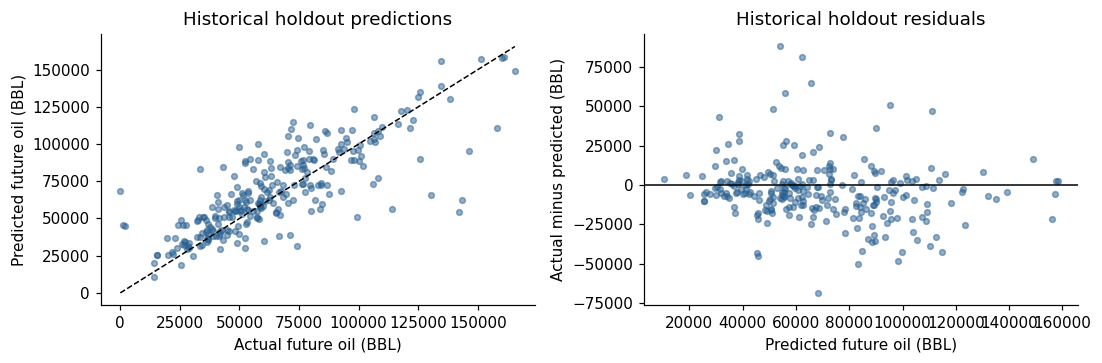

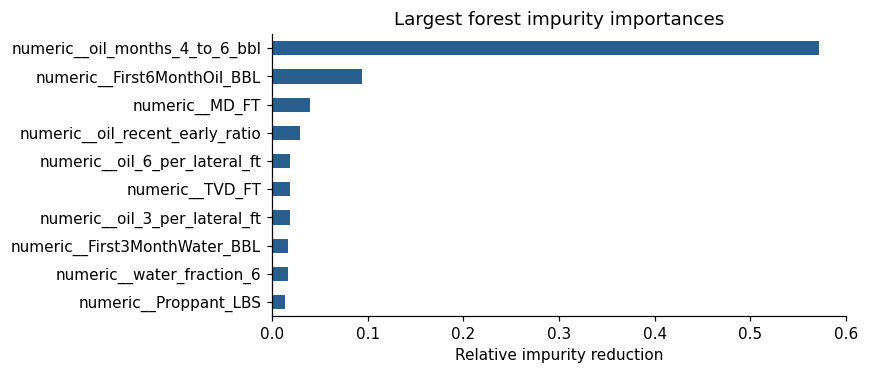

In [21]:
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
axes[0].scatter(yt,pred,s=14,alpha=.5,color='#285f8f')
limit=max(max(yt),max(pred)); axes[0].plot([0,limit],[0,limit],'k--',linewidth=1)
axes[0].set(title='Historical holdout predictions',xlabel='Actual future oil (BBL)',ylabel='Predicted future oil (BBL)')
axes[1].scatter(pred,yt-pred,s=14,alpha=.5,color='#285f8f'); axes[1].axhline(0,color='black',linewidth=1)
axes[1].set(title='Historical holdout residuals',xlabel='Predicted future oil (BBL)',ylabel='Actual minus predicted (BBL)')
plt.tight_layout(); plt.show()
names=model.named_steps['preprocess'].get_feature_names_out()
estimator=model.named_steps['model']
values=estimator.feature_importances_ if hasattr(estimator,'feature_importances_') else np.abs(estimator.coef_)
importance=pd.Series(values,index=names).sort_values().tail(10)
fig,ax=plt.subplots(figsize=(8,3.5)); importance.plot.barh(ax=ax,color='#285f8f')
ax.set(title='Largest forest impurity importances',xlabel='Relative impurity reduction')
plt.tight_layout(); plt.show()

Impurity importance describes how the fitted forest used its inputs. Correlated production variables can share importance, and high-cardinality inputs can receive inflated values; this is not a causal explanation.

## 8. Export and reload the complete pipeline

Persist feature engineering, imputation, encoding and the fitted regressor together. The exported pipeline accepts raw month-six fields. This avoids implementing different preprocessing in training and serving. Notebook reruns write to a separate folder so the packaged artifact and reports remain unchanged.

In [22]:
output=ROOT/'reports/notebook-run'; output.mkdir(parents=True,exist_ok=True)
joblib.dump(model,output/'model.joblib')
loaded=joblib.load(output/'model.joblib')
packaged=joblib.load(ROOT/'models/model.joblib')
np.testing.assert_allclose(loaded.predict(Xt),model.predict(Xt),rtol=0,atol=1e-8)
np.testing.assert_allclose(packaged.predict(Xt),loaded.predict(Xt),rtol=0,atol=1e-8)
print('Export/reload and packaged-artifact parity: PASS')
print('Pipeline steps:',list(loaded.named_steps))

Export/reload and packaged-artifact parity: PASS
Pipeline steps: ['domain_features', 'preprocess', 'model']


## 9. Serve a prediction with FastAPI

`POST /predict` accepts a `features` object. Six-month oil must be a nonnegative number; optional fields may be omitted or null. Unknown/future predictors and invalid values are rejected. The response reports incremental oil, cumulative first-year oil and observed six-month oil.

Callers must provide an actual month-six snapshot, verify the study domain, and omit completion attributes when their dates are missing or late. The API cannot independently verify dates or vendor revisions.

In [23]:
from fastapi.testclient import TestClient
from predict import app
client=TestClient(app)
sample={k:None if pd.isna(v) else v.item() if hasattr(v,'item') else v for k,v in Xt.iloc[0].items()}
response=client.post('/predict',json={'features':sample})
assert response.status_code==200,response.text
assert response.json()['predicted_months_7_to_12_oil_bbl']==round(float(pred[0]),2)
display(response.json())
assert client.post('/predict',json={'features':{'First6MonthOil_BBL':1000,'First12MonthOil_BBL':2000}}).status_code==422
print('API prediction parity and future-field rejection: PASS')

{'predicted_months_7_to_12_oil_bbl': 56052.42,
 'predicted_12_month_cumulative_oil_bbl': 117332.42,
 'actual_first_6_month_oil_bbl': 61280.0}

API prediction parity and future-field rejection: PASS


## 10. Run in Docker and reproduce

From the project root:
```text
python train.py --output reports/reproduction
python verify_project.py --rerun reports/reproduction --allow-platform-differences
python -m pytest -q
docker build -t wolfcamp-midterm-submission .
docker run --rm -p 127.0.0.1:8000:8000 wolfcamp-midterm-submission
```
In another terminal:
```text
python examples/smoke_api.py --url http://127.0.0.1:8000
python examples/verify_api_parity.py --url http://127.0.0.1:8000
```
Open `http://127.0.0.1:8000/docs`. The runtime image includes the saved model, source and pinned dependencies. In the reference Docker/Linux environment, full-search verification also passes without the platform-differences flag. Windows reruns report nonselected XGBoost differences explicitly while keeping selected-pipeline checks strict. Local Docker verification and clean-copy checks are documented in `VERIFICATION.md`.

## 11. Conclusion

This project delivers an end-to-end machine-learning workflow for forecasting **future incremental oil production** from a well's first six months of measurements. Five regression families were evaluated with the same feature definitions, fold-fitted preprocessing and purged chronological splits. The 49 configurations produced 147 fold fits, making the model-selection decision traceable to recorded results.

**Random Forest was selected by mean training-CV RMSE: 25,623.00 BBL**, compared with 25,981.49 for the best XGBoost configuration in the Docker/Linux reference run. The selected forest uses 240 trees, a minimum leaf size of five and feature sampling of 0.75. After refitting on 1,500 label-mature wells from 2014–19, its evaluation on 264 historical 2020–21 wells gave **RMSE 19,158.43 BBL, MAE 13,273.65 BBL and R² 0.6202**. The R² describes variation explained within this cohort; it is not a percentage-accuracy measure for individual forecasts.

The forest reduced historical-holdout RMSE by **6.72% against the fitted recent-rate benchmark** and **44.50% against the training-median benchmark**. Its MAE was 17.76 BBL higher than the recent-rate benchmark's 13,255.89 BBL, a difference of about 0.13%. The benefit is a lower squared-error aggregate, whose weighting emphasizes larger misses; average absolute error is very similar. Reporting both metrics avoids overstating the benefit of the more complex model.

The fitted forest places its largest impurity-based importances on months 4–6 oil and total first-six-month oil. This is consistent with recent measured production carrying predictive information about subsequent output. These importances describe the fitted model, and correlated predictors prevent interpreting them as independent or causal effects.

The deliverable includes explicit preprocessing visualizations, model-specific tuning code, saved evaluation results, a serialized feature/preprocessing/model pipeline, and a FastAPI service running in Docker. Saved-pipeline/API parity checks establish that the deployed service applies the evaluated transformations and estimator. The resulting model is a reproducible estimate of future oil for the studied population, with the evaluation limits below.

## 12. Limitations and their implications

- **Previously inspected historical holdout.** The 2020–21 cohort was examined during earlier development. Keeping its labels out of this search does not restore an independent untouched test. The reported results are retrospective evidence; a later, genuinely unseen cohort is needed to establish prospective performance.
- **Restricted population and limited later-year coverage.** The study includes eligible Wolfcamp/Delaware Basin wells within the stated depth/lateral bounds and with available twelve-month outcomes. Of the 264 holdout wells, 247 are from 2020 and only 17 from 2021. Aggregate scores therefore provide limited evidence about 2021, newer operating conditions, other regions or excluded well types. Individual and subgroup performance may differ substantially from the averages.
- **Incomplete historical availability information.** Completion-date masking and calendar-label purging reduce identifiable timing problems, but actual reporting dates, vendor revisions and complete point-in-time snapshots are unavailable. The study cannot certify that every recorded input and training label existed exactly as shown at the forecast date.
- **Heavy missingness in some predictors.** FracStages is 90.6% missing in the 2014–18 training cohort. Median filling creates a concentration at the fitted median and compresses that predictor's marginal spread. Missingness flags preserve the distinction between observed and filled values, but cannot recover the lost measurements. The before/after figures document this effect; they do not establish the accuracy of unknown-value reconstruction.
- **Finite search and uncertain ranking.** Each tunable family received twelve configurations. The forest's mean-CV lead over XGBoost is about 1.38%, and no repeated-seed study or uncertainty interval establishes that this ranking is statistically reliable. The conclusion applies to the tested searches and protocol, rather than all possible configurations of these algorithms.
- **Point predictions and unmeasured error variation.** RMSE and MAE summarize errors across the cohort. The service supplies no calibrated prediction interval, and error by location, production band, missingness pattern and other subgroups has not been validated comprehensively. A single forecast should not be treated as a guaranteed production volume.
- **Platform-dependent XGBoost results.** Twelve XGBoost trial scores differed between Windows and Linux despite the recorded package versions and seeds. Both runs selected the same forest and reproduced its final metrics/predictions, but the nonselected-family scores are not interchangeable. The published notebook and tuning tables use Docker/Linux; both observed runs remain documented.
- **Forecast-time input contract.** The model is conditional on six months of observed production and the defined study domain. API type checks and fitted imputation allow incomplete requests to be processed, but do not establish that a supplied snapshot is historically valid or representative of the training population. Performance under changed input distributions has not been established.

## 13. Next steps

1. **Evaluate on newly collected later wells before further model selection.** Freeze the current pipeline and use independently held-out outcomes with dated input snapshots and reporting timestamps. This would test prospective generalization directly.
2. **Improve input completeness and availability checks.** Audit missing completion records, source revisions and forecast-time metadata. Reassess sparse predictors and missingness-sensitive performance using training-only experiments followed by independent evaluation.
3. **Measure reliability beyond aggregate scores.** Report errors by year, location, production range and missingness pattern with sample counts and uncertainty estimates; develop and validate prediction intervals.
4. **Check model-selection stability and deployment drift.** Repeat the declared searches across seeds in a fixed environment, resolve the XGBoost reproducibility differences, and monitor input distributions and realized errors as later outcomes become available.

AI assisted implementation, documentation and review; the author remains responsible for the decisions and results.